# 02 - Inspeccion del dataset

Conteos por variedad y split, distribucion de tamanos de racimo, verificacion
de que las imagenes con mascara tienen todas sus cajas enmascaradas y overlays
de mascaras GT por variedad.

In [1]:
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

WGISD_DIR = Path("../data/wgisd")
IMAGES_DIR = WGISD_DIR / "data"

VARIETY_COLOR = {"CDY": "blanca", "SVB": "blanca", "CFR": "tinta", "CSV": "tinta", "SYH": "tinta"}

train_list = (WGISD_DIR / "train.txt").read_text().splitlines()
test_list = (WGISD_DIR / "test.txt").read_text().splitlines()

## Conteos por variedad y split

In [2]:
def variety_of(name: str) -> str:
    return name[:3]

for split_name, names in [("train", train_list), ("test", test_list)]:
    counts = Counter(variety_of(n) for n in names)
    print(split_name, dict(counts))

train {'CDY': 50, 'SVB': 51, 'CSV': 48, 'CFR': 55, 'SYH': 38}
test {'CSV': 9, 'SYH': 10, 'SVB': 14, 'CFR': 10, 'CDY': 15}


## Distribucion de tamanos de racimo (area de caja, en pixeles)

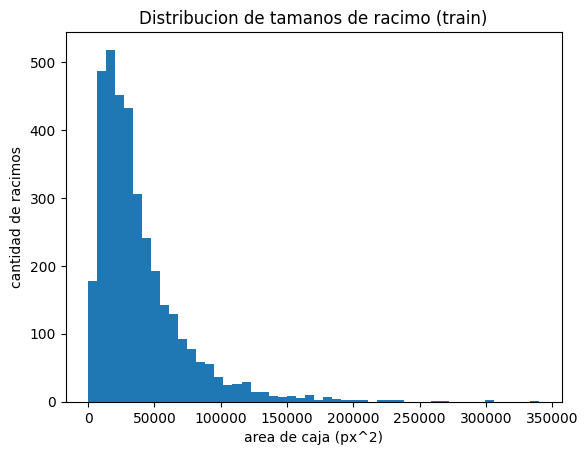

percentiles (5/25/50/75/95): [  6882.2726151   16479.34945413  29527.120896    50265.81583785
 103132.36707705]


In [3]:
def box_areas_px(names):
    areas = []
    for name in names:
        img = Image.open(IMAGES_DIR / f"{name}.jpg")
        W, H = img.size
        boxes = np.loadtxt(IMAGES_DIR / f"{name}.txt").reshape(-1, 5)
        for _, cx, cy, w, h in boxes:
            areas.append((w * W) * (h * H))
    return np.array(areas)

train_areas = box_areas_px(train_list)
plt.hist(train_areas, bins=50)
plt.xlabel("area de caja (px^2)")
plt.ylabel("cantidad de racimos")
plt.title("Distribucion de tamanos de racimo (train)")
plt.show()

print("percentiles (5/25/50/75/95):", np.percentile(train_areas, [5, 25, 50, 75, 95]))

## Imagenes con mascara: ¿todas las cajas tienen mascara?

Si hubiera cajas sin mascara en imagenes parcialmente anotadas, una prediccion
que cae sobre ellas no deberia contarse como falso positivo al evaluar mascaras.

In [4]:
def check_full_mask_coverage(names):
    mismatches = []
    for name in names:
        npz_p = IMAGES_DIR / f"{name}.npz"
        if not npz_p.exists():
            continue
        boxes = np.loadtxt(IMAGES_DIR / f"{name}.txt").reshape(-1, 5)
        npz = np.load(npz_p)
        M = npz[list(npz.keys())[0]]
        if M.shape[2] != boxes.shape[0]:
            mismatches.append((name, boxes.shape[0], M.shape[2]))
    return mismatches

mism_train = check_full_mask_coverage(train_list)
mism_test = check_full_mask_coverage(test_list)
print("desalineos train:", mism_train)
print("desalineos test:", mism_test)

desalineos train: []
desalineos test: []


## Overlays de mascaras GT, una por variedad

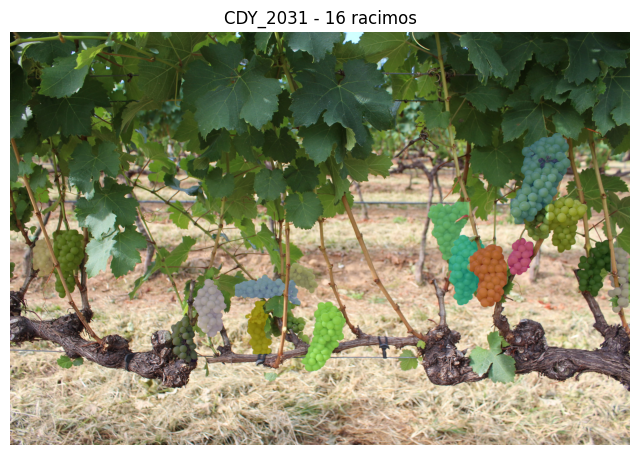

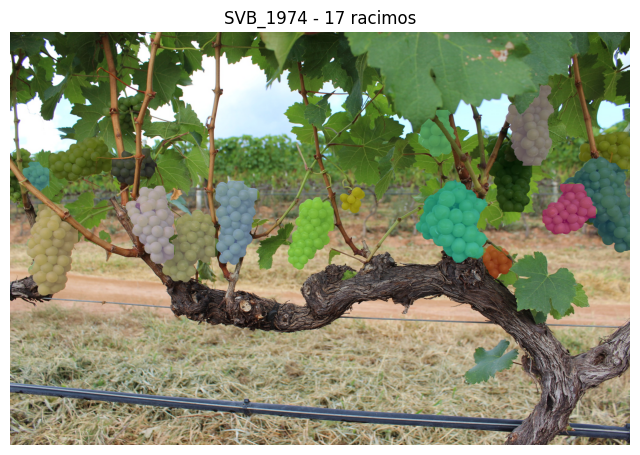

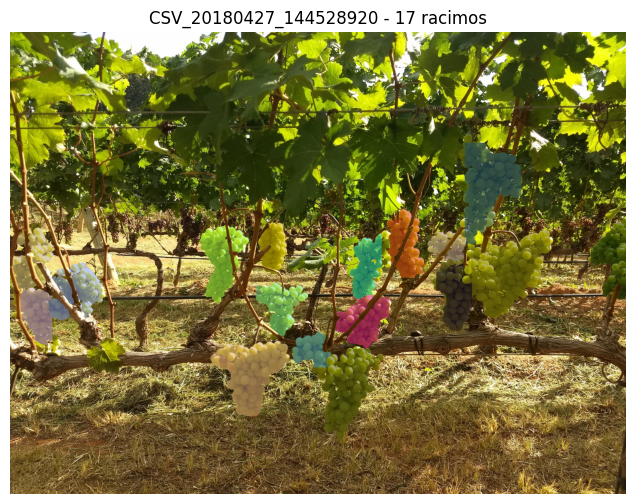

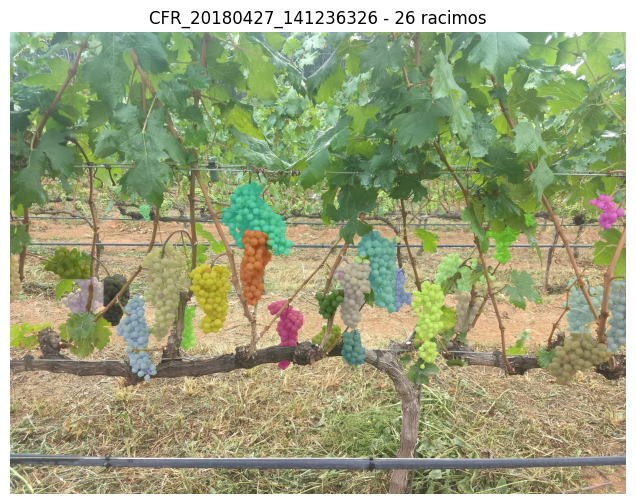

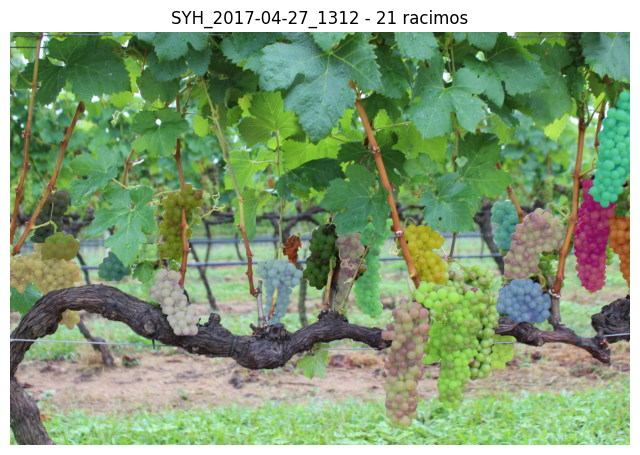

In [5]:
def overlay_gt_masks(name, alpha=0.5):
    img = np.array(Image.open(IMAGES_DIR / f"{name}.jpg"))
    npz_p = IMAGES_DIR / f"{name}.npz"
    if not npz_p.exists():
        print(name, "sin mascara")
        return
    npz = np.load(npz_p)
    M = npz[list(npz.keys())[0]]
    overlay = img.copy()
    rng = np.random.default_rng(0)
    for i in range(M.shape[2]):
        color = rng.integers(0, 255, size=3)
        mask = M[:, :, i].astype(bool)
        overlay[mask] = (overlay[mask] * (1 - alpha) + color * alpha).astype(np.uint8)
    plt.figure(figsize=(8, 6))
    plt.imshow(overlay)
    plt.title(f"{name} - {M.shape[2]} racimos")
    plt.axis("off")
    plt.show()

one_per_variety = {}
for name in train_list:
    v = variety_of(name)
    if v not in one_per_variety and (IMAGES_DIR / f"{name}.npz").exists():
        one_per_variety[v] = name

for v, name in one_per_variety.items():
    overlay_gt_masks(name)